# VoltammoMan from Python – a tutorial

This notebook shows how to use VoltammoMan as a Python library:

1. example data and reading a curve,
2. evaluating one curve and its control plot,
3. batch evaluation of a folder and saving the table,
4. flagged curves,
5. baseline methods and settings,
6. evaluating your own arrays,
7. the simulator.

All curves here are **synthetic** (made by the built-in simulator in the NOVA export format), so the
notebook runs anywhere. To use your own data, replace `demo_curves` by the folder with your NOVA
exports.

Requirements: `pip install -e ".[gui]"` in the repository root (or just `voltammoman`) and Jupyter
(`pip install jupyter`). Run the notebook from the `examples/` folder.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import voltammoman as vom
from voltammoman.plot import plot_result

pd.set_option("display.width", 160)
print("VoltammoMan", vom.__version__)

VoltammoMan 0.1.0


## 1. Example data and reading a curve

`write_examples` writes a few simulated curves into a folder: an oxidation-first couple
(ferrocyanide-like, `sim-ox-…`) and a reduction-first couple (hexaammineruthenium-like, `sim-red-…`),
each with fast to slow electron transfer (`k0` in cm/s), plus a curve without any redox couple.
They include a charging current, a sloped background and a little noise, as on real carbon electrodes.

In [2]:
from voltammoman.examples import write_examples

folder = Path("demo_curves")
files = write_examples(folder)
[f.name for f in files]

['sim-ox-k0_1e-1.txt',
 'sim-ox-k0_1e-2.txt',
 'sim-ox-k0_3e-3.txt',
 'sim-ox-k0_1e-3.txt',
 'sim-ox-k0_3e-4.txt',
 'sim-red-k0_1e-1.txt',
 'sim-red-k0_1e-2.txt',
 'sim-red-k0_1e-3.txt',
 'sim-no-peak.txt']

Each file has exactly the layout of a NOVA ASCII export (`;` separator, potential in V, current in A):

In [3]:
print("\n".join((folder / "sim-ox-k0_1e-2.txt").read_text().splitlines()[:4]))

Potential applied (V);Smoothed WE(1).Current (A)
0.00244140625;1.0790792560324E-06
0.0048828125;1.11047565564097E-06
0.00732421875;1.11294728847226E-06


`read_curve` returns a DataFrame with columns `E` [V] and `I` [A]. It also understands other
separators, a decimal comma and files with extra columns (time, scan number, …).

In [4]:
cv = vom.read_curve(folder / "sim-ox-k0_1e-2.txt")
print(cv.shape)
cv.head()

(984, 2)


,E,I
0,0.002441,0.000001
1,0.004883,0.000001
2,0.007324,0.000001
3,0.009766,0.000001
4,0.012207,0.000001


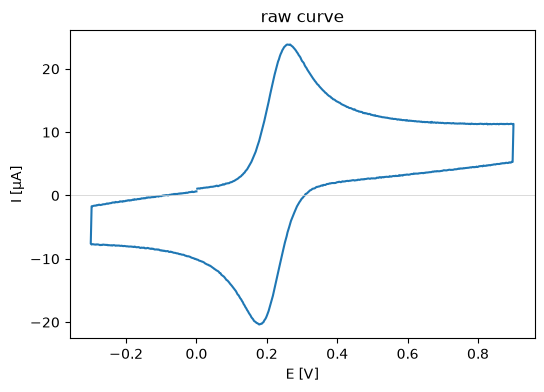

In [5]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(cv["E"], cv["I"] * 1e6)
ax.set(xlabel="E [V]", ylabel="I [µA]", title="raw curve")
ax.axhline(0, color="0.8", lw=.5);

## 2. Evaluating one curve

`analyze_file` reads and evaluates a file. The result has a dictionary `values` with all numbers
(potentials in V, currents in A) and the intermediate objects used by the control plot.

In [6]:
res = vom.analyze_file(folder / "sim-ox-k0_1e-2.txt")
pd.Series(res.values)

file               sim-ox-k0_1e-2.txt
n_points                          984
E_min                       -0.300293
E_max                        0.900879
first_peak                     anodic
EpA                          0.258789
EpC                          0.178223
dEp                          0.080566
E_half                       0.218506
IpA                          0.000021
IpC                         -0.000021
ratio                        1.008477
ratio_nicholson              1.043993
wA                           0.062027
wC                           0.064913
IpA_raw                      0.000024
IpC_raw                      -0.00002
baseline                     flattest
flags                                
error                                
dtype: object

The most important values:

| Key | Meaning |
|---|---|
| `EpA`, `EpC`, `dEp` | anodic / cathodic peak potential and their separation (kinetics) |
| `IpA`, `IpC` | peak currents measured from the baseline (`IpC` < 0) |
| `ratio` | IpA/\|IpC\| from the baseline-corrected currents |
| `ratio_nicholson` | IpA/\|IpC\| by Nicholson's method, **recommended** measure of reversibility |
| `flags` | problems found; empty if everything is fine |

The control plot shows both peaks, their baselines (dashed; the thick part is the fitted region) and
the peak heights. Grey crosses and the square are the reference levels used by Nicholson's formula.

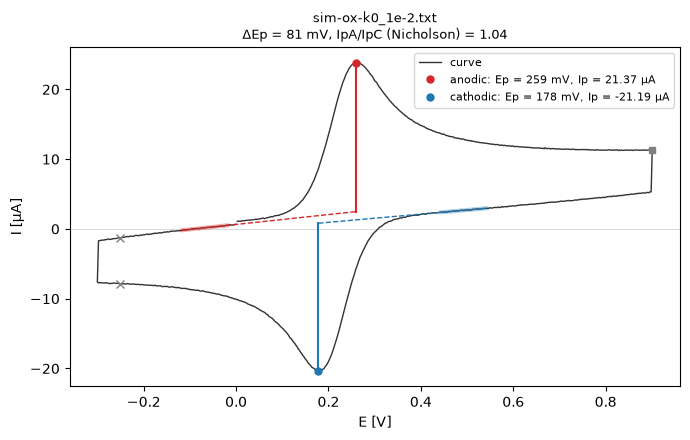

In [7]:
plot_result(res);

## 3. Batch evaluation of a folder

`analyze_files` takes files and/or folders and returns one row per file. A file that cannot be
read does not stop the batch; its row gets an `error` message instead.

In [8]:
df = vom.analyze_files(folder)            # all *.txt files; pattern=..., recursive=True also possible
df[["file", "EpA", "EpC", "dEp", "IpA", "IpC", "ratio", "ratio_nicholson", "flags"]]

,file,EpA,EpC,dEp,IpA,IpC,ratio,ratio_nicholson,flags
0,sim-no-peak.txt,0.788574,0.136719,0.651855,1.117905e-07,-1.025654e-07,1.089943,NaN,A:weak_peak;C:weak_peak
1,sim-ox-k0_1e-1.txt,0.249023,0.192871,0.056152,2.252969e-05,-2.217126e-05,1.016166,1.049348,
2,sim-ox-k0_1e-2.txt,0.258789,0.178223,0.080566,2.136597e-05,-2.118638e-05,1.008477,1.043993,
3,sim-ox-k0_1e-3.txt,0.319824,0.117188,0.202637,1.512774e-05,-1.720676e-05,0.879174,0.919771,
4,sim-ox-k0_3e-3.txt,0.280762,0.156250,0.124512,1.755524e-05,-1.908782e-05,0.919709,0.953845,
5,sim-ox-k0_3e-4.txt,0.380859,0.061035,0.319824,1.242510e-05,-1.546439e-05,0.803465,0.833309,
6,sim-red-k0_1e-1.txt,-0.139160,-0.200195,0.061035,2.166510e-05,-2.198531e-05,0.985435,0.960298,
7,sim-red-k0_1e-2.txt,-0.129395,-0.207520,0.078125,2.034097e-05,-2.099094e-05,0.969035,0.955647,
8,sim-red-k0_1e-3.txt,-0.078125,-0.278320,0.200195,1.417737e-05,-1.724962e-05,0.821895,0.940709,


For reading, it is handy to convert to mV and µA:

In [9]:
nice = df.set_index("file")[["dEp", "IpA", "IpC", "ratio_nicholson", "flags"]].copy()
nice["dEp"] = (nice["dEp"] * 1e3).round(1)                     # mV
nice[["IpA", "IpC"]] = (nice[["IpA", "IpC"]] * 1e6).round(2)   # µA
nice.rename(columns={"dEp": "ΔEp [mV]", "IpA": "IpA [µA]", "IpC": "IpC [µA]"})

,ΔEp [mV],IpA [µA],IpC [µA],ratio_nicholson,flags
file,,,,,
sim-no-peak.txt,651.9,0.11,-0.10,NaN,A:weak_peak;C:weak_peak
sim-ox-k0_1e-1.txt,56.2,22.53,-22.17,1.049348,
sim-ox-k0_1e-2.txt,80.6,21.37,-21.19,1.043993,
sim-ox-k0_1e-3.txt,202.6,15.13,-17.21,0.919771,
sim-ox-k0_3e-3.txt,124.5,17.56,-19.09,0.953845,
sim-ox-k0_3e-4.txt,319.8,12.43,-15.46,0.833309,
sim-red-k0_1e-1.txt,61.0,21.67,-21.99,0.960298,
sim-red-k0_1e-2.txt,78.1,20.34,-20.99,0.955647,
sim-red-k0_1e-3.txt,200.2,14.18,-17.25,0.940709,


`save_table` writes `.xlsx` (with a second sheet describing the columns) or `.csv`:

In [10]:
vom.save_table(df, "demo_results.xlsx")
vom.save_table(df, "demo_results.csv")
pd.read_excel("demo_results.xlsx", sheet_name="columns").head(8)

,column,meaning
0,file,file name
1,n_points,number of points of the evaluated cycle
2,E_min,lower vertex potential [V]
3,E_max,upper vertex potential [V]
4,first_peak,which peak was recorded first in the cycle (fo...
5,EpA,anodic peak potential [V]
6,EpC,cathodic peak potential [V]
7,dEp,peak separation EpA - EpC [V]


## 4. Flagged curves

Curves with a non-empty `flags` column need a look at the control plot. Possible flags (prefixed
`A:` / `C:` for the anodic / cathodic peak):

- `broad_peak` – the peak is very broad, its height depends strongly on the baseline,
- `weak_peak` – the peak is small compared with the current range or the noise,
- `no_peak`, `peak_at_vertex`, `nonpositive_height`, `no_baseline` – no usable peak.

The example `sim-no-peak.txt` contains no redox couple at all, only background and noise:

In [11]:
flagged = df[df["flags"] != ""]
flagged[["file", "flags", "ratio_nicholson"]]

,file,flags,ratio_nicholson
0,sim-no-peak.txt,A:weak_peak;C:weak_peak,NaN


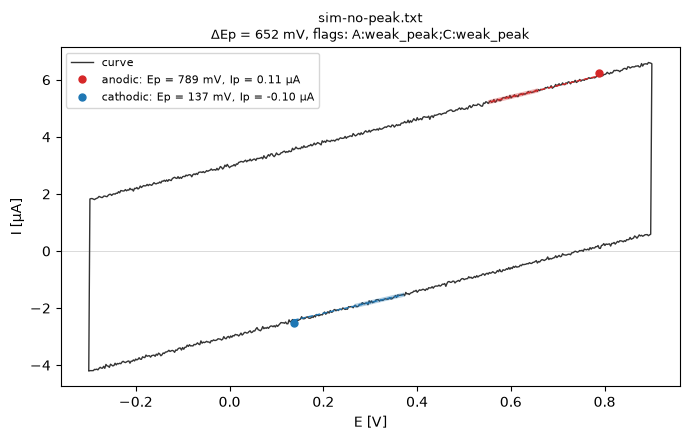

In [12]:
plot_result(vom.analyze_file(folder / "sim-no-peak.txt"));

Control plots for all curves can be saved at once (one PNG per curve):

In [13]:
from voltammoman.plot import save_plots

results = [vom.analyze_file(f) for f in sorted(folder.glob("*.txt"))]
paths = save_plots(results, "demo_plots")
len(paths), paths[0]

(9, PosixPath('demo_plots/sim-no-peak.png'))

## 5. Baseline methods and settings

Three baseline methods are available (`vom.BASELINES`):

- `flattest` (default) – line through the most linear part of the background before the peak,
- `linear` – line through a fixed window 150–350 mV before the peak,
- `tangent` – tangent at the foot of the wave.

On a slow (broad) wave the choice matters most:

,dEp,IpA,IpC,ratio,ratio_nicholson
method,,,,,
flattest,0.319824,0.000012,-0.000015,0.803465,0.833309
linear,0.314941,0.000011,-0.000008,1.343756,0.747314
tangent,0.336914,0.000018,-0.000018,0.988154,1.172813


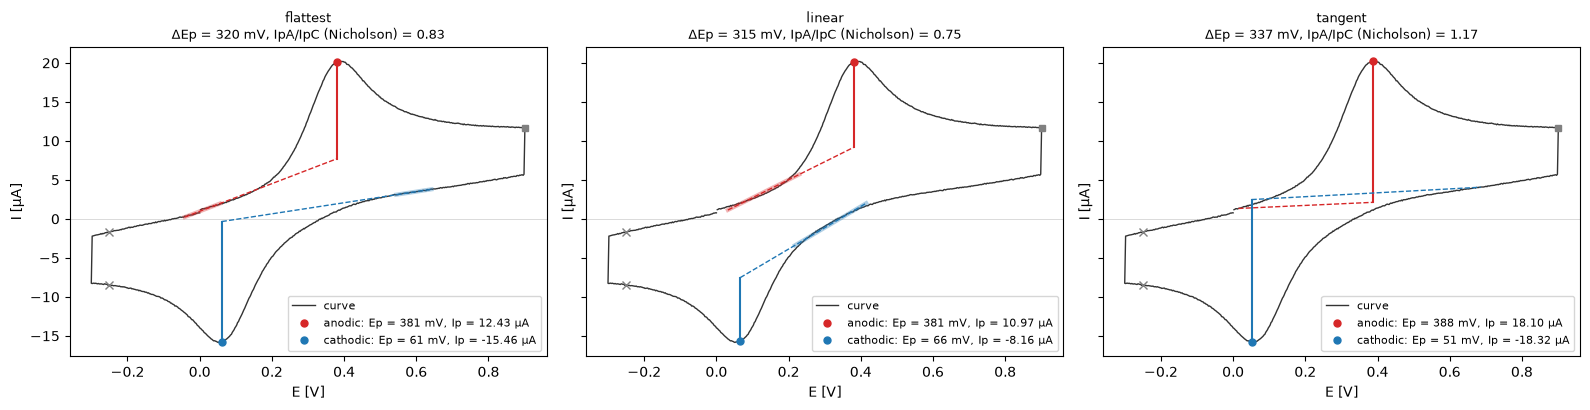

In [14]:
slow = folder / "sim-ox-k0_3e-4.txt"
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
rows = []
for ax, method in zip(axes, vom.BASELINES):
    r = vom.analyze_file(slow, baseline=method)
    plot_result(r, ax=ax, title=method)
    rows.append({"method": method, **{k: r.values[k] for k in ["dEp", "IpA", "IpC", "ratio", "ratio_nicholson"]}})
pd.DataFrame(rows).set_index("method")

With peaks this broad (ΔEp ≈ 320 mV) the methods disagree considerably. The wave starts so early
that the background windows of `flattest` and `linear` already lie on its foot, so they give lower
peak currents; `tangent` gives the highest. For comparison, the same couple scanned once from rest
(where the true baseline is zero) has an anodic peak of ≈ 17.8 µA. For typical peaks (ΔEp below
≈ 200 mV) the methods agree much better and `flattest` is closest to manual evaluation in NOVA.
Whatever the method, peak currents of very broad waves should be taken with caution.

The search is controlled by `PeakSettings` (potentials in V). For example, a wider gap between the
baseline region and the peak and a narrower window:

In [15]:
vom.PeakSettings()   # the defaults

PeakSettings(edge=0.03, search=0.02, gap=0.1, width=0.1, smooth=11, base_from=0.35, base_to=0.15, broad=0.2, min_rel=0.05, min_snr=10.0, min_points=8)

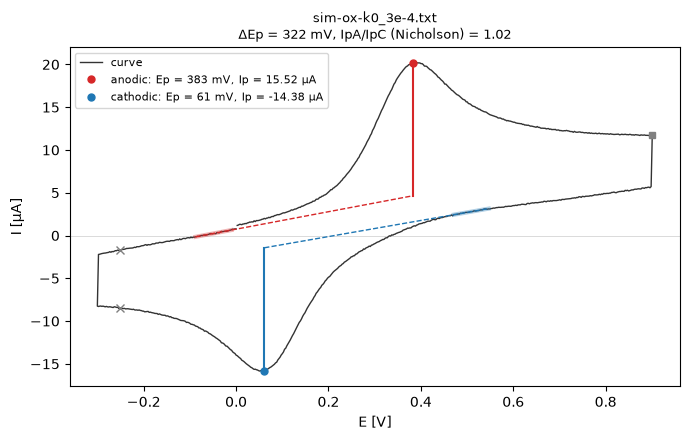

In [16]:
s = vom.PeakSettings(gap=0.15, width=0.08)
r = vom.analyze_file(slow, settings=s)
plot_result(r);

Multi-cycle files: by default the last complete cycle is evaluated; choose another one by
`cycle=` (zero-based, negative counts from the end), e.g. `vom.analyze_file(path, cycle=0)`.

## 6. Evaluating your own arrays

If your data come from another source, pass the potential and current arrays directly to
`analyze_curve` (V and A, one or more complete cycles in the recorded order):

In [17]:
E, I = cv["E"].to_numpy(), cv["I"].to_numpy()       # any two numpy arrays
r = vom.analyze_curve(E, I, baseline="flattest", name="my curve")
{k: r.values[k] for k in ["EpA", "EpC", "dEp", "IpA", "IpC", "ratio_nicholson", "flags"]}

{'EpA': np.float64(0.2587890625),
 'EpC': np.float64(0.17822265625),
 'dEp': np.float64(0.08056640625),
 'IpA': np.float64(2.1365972322572042e-05),
 'IpC': np.float64(-2.118637551963342e-05),
 'ratio_nicholson': np.float64(1.0439932226609663),
 'flags': ''}

## 7. The simulator

`simulate_cv` simulates a one-electron couple (Butler–Volmer kinetics, planar diffusion) with an
optional charging current (`Cdl`, F/cm²), uncompensated resistance (`Ru`, Ω), sloped background
(`slope`, A/V), offset and noise. The default potential program reproduces a NOVA export
(0 V → 0.9 V → −0.3 V → 0 V in 2.44 mV steps); `potential_program` makes other windows.

Slower electron transfer (smaller `k0`) pulls the peaks apart:

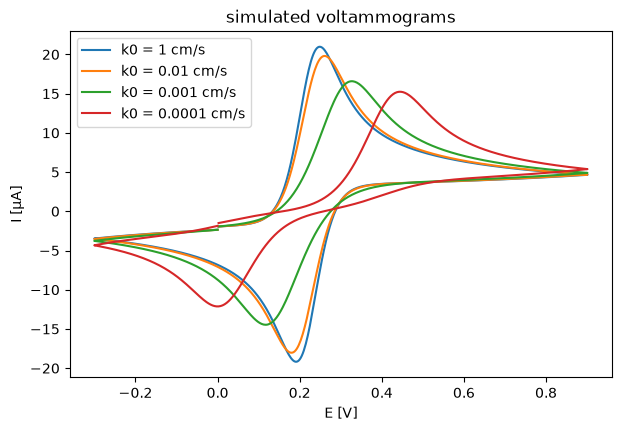

In [18]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for k0 in [1, 1e-2, 1e-3, 1e-4]:
    E, I = vom.simulate_cv(k0=k0, E0=0.22)
    ax.plot(E, I * 1e6, label=f"k0 = {k0:g} cm/s")
ax.set(xlabel="E [V]", ylabel="I [µA]", title="simulated voltammograms")
ax.legend();

The simulator reproduces textbook results, e.g. Nicholson's relation between the kinetic
parameter ψ = k0 / sqrt(π D n v F / RT) and ΔEp (25 °C, α = 0.5), and the Randles–Ševčík peak
current of a reversible wave:

In [19]:
from voltammoman.simulate import F, R

D, v, T = 7e-6, 0.1, 298.15
nicholson = {20: 61, 7: 63, 5: 65, 3: 68, 2: 72, 1: 84, 0.75: 92, 0.5: 105, 0.35: 121, 0.25: 141, 0.1: 212}
rows = []
for psi, dEp_table in nicholson.items():
    k0 = psi * np.sqrt(np.pi * D * v * F / (R * T))
    E, I = vom.simulate_cv(k0=k0, D=D, scan_rate=v, T=T)
    rows.append(dict(psi=psi, k0=k0, dEp_simulated=vom.analyze_curve(E, I).values["dEp"] * 1e3,
                     dEp_Nicholson=dEp_table))
print("Randles-Sevcik:", round(vom.randles_sevcik() * 1e6, 2), "µA;  simulated reversible IpA:",
      round(vom.analyze_curve(*vom.simulate_cv(k0=1)).values["IpA"] * 1e6, 2), "µA")
pd.DataFrame(rows).round(4)

Randles-Sevcik: 22.48 µA;  simulated reversible IpA: 22.55 µA


,psi,k0,dEp_simulated,dEp_Nicholson
0,20.00,0.1850,58.5938,61
1,7.00,0.0648,61.0352,63
2,5.00,0.0463,61.0352,65
3,3.00,0.0278,65.9180,68
4,2.00,0.0185,70.8008,72
5,1.00,0.0093,80.5664,84
6,0.75,0.0069,90.3320,92
7,0.50,0.0046,104.9805,105
8,0.35,0.0032,119.6289,121
9,0.25,0.0023,141.6016,141


A simulated curve can be written in the NOVA format and evaluated like a measured one. This is
also a quick way to check how well the evaluation recovers known parameters, e.g. with more noise
and a larger capacitance:

ΔEp: 200.2 mV (noise-free: 207.5 mV)
IpA: 17.90 µA (noise-free: 17.78 µA)
IpA/IpC (Nicholson): 1.06


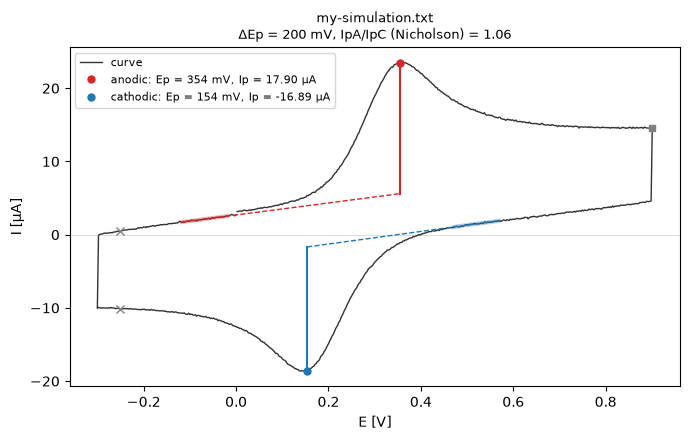

In [20]:
E, I = vom.simulate_cv(k0=1e-3, Cdl=5e-4, slope=5e-6, noise=5e-8, seed=0)
path = vom.write_curve("demo_curves/my-simulation.txt", E, I)
r = vom.analyze_file(path)
truth = vom.analyze_curve(*vom.simulate_cv(k0=1e-3)).values   # the same couple without background and noise
print(f"ΔEp: {r.values['dEp'] * 1e3:.1f} mV (noise-free: {truth['dEp'] * 1e3:.1f} mV)")
print(f"IpA: {r.values['IpA'] * 1e6:.2f} µA (noise-free: {truth['IpA'] * 1e6:.2f} µA)")
print(f"IpA/IpC (Nicholson): {r.values['ratio_nicholson']:.2f}")
plot_result(r);

## The same from the command line

```bash
vom examples demo_curves                     # example data
vom analyze demo_curves -o results.xlsx --plots
vom analyze demo_curves -b linear --gap 0.15 # another baseline method / settings
vom simulate slow.txt --k0 1e-3 --Cdl 300 --noise 0.03 --seed 1
vom gui                                      # graphical interface in the browser
```